# ДЗ 2

In [1]:
import os, re, json, time, hashlib, threading
from pathlib import Path
from dataclasses import dataclass, field
from concurrent.futures import ThreadPoolExecutor
from unittest.mock import patch
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pydantic import BaseModel, Field
from pymilvus import MilvusClient

try:
    from dotenv import load_dotenv, find_dotenv
    load_dotenv(find_dotenv(usecwd=True))  # ищет .env вверх от текущей папки: работает и из корня, и из home_works
except ImportError:
    pass
assert os.getenv("OPENROUTER_API_KEY"), "нет ключа: положите его в .env рядом с ноутбуком"

CHAT_URL = "https://openrouter.ai/api/v1/chat/completions"
EMBED_URL = "https://openrouter.ai/api/v1/embeddings"
HEADERS = {"Authorization": f"Bearer {os.environ['OPENROUTER_API_KEY']}", "X-Title": "agents-course-hw02"}
MODELS = {"cheap": "openai/gpt-4o-mini", "mid": "anthropic/claude-haiku-4.5", "strong": "anthropic/claude-sonnet-4.6"}
EMBED_MODEL, DIM = "openai/text-embedding-3-small", 512
COLORS = {"violet": "#5436A3", "amber": "#F09000", "teal": "#00838F"}

# корень репозитория ищем вверх от текущей папки: файл можно запускать и из корня, и из home_works
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "corpus_2026.jsonl").exists())
DATA, IMG, MEMORY_DIR = ROOT / "data", ROOT / "img", ROOT / "memory"
for p in (IMG, MEMORY_DIR):
    p.mkdir(parents=True, exist_ok=True)


@dataclass
class Ledger:
    calls: list = field(default_factory=list)
    local: threading.local = field(default_factory=threading.local)

    def add(self, tag, model, usage, seconds=0.0):
        cost = usage.get("cost") or 0.0
        self.calls.append({"tag": tag, "model": model.split("/")[-1], "prompt": usage.get("prompt_tokens", 0),
                           "completion": usage.get("completion_tokens", 0), "cost": cost, "seconds": round(seconds, 2)})
        self.local.spent = self.mine + cost
        return cost

    @property
    def total(self):
        return sum(c["cost"] for c in self.calls)

    @property
    def mine(self):
        return getattr(self.local, "spent", 0.0)

    def table(self):
        frame = pd.DataFrame(self.calls, columns=["tag", "model", "prompt", "completion", "cost", "seconds"])
        return frame.groupby(["tag", "model"]).agg(calls=("cost", "size"), prompt=("prompt", "sum"),
                                                   completion=("completion", "sum"), cost=("cost", "sum")).round(5)


ledger = Ledger()


def post_with_retry(url, body, attempts=5):
    problem = "нет ответа"
    for attempt in range(attempts):
        try:
            r = requests.post(url, json=body, headers=HEADERS, timeout=120)
            if r.status_code == 200:
                return r.json()
            problem = f"HTTP {r.status_code}: {r.text[:200]}"
            if r.status_code not in (429, 500, 502, 503, 504):
                break
        except requests.RequestException as e:
            problem = type(e).__name__
        time.sleep(2.0 * (attempt + 1))
    raise RuntimeError(problem)


def chat(messages, model, tools=None, tag="chat"):
    body = {"model": model, "messages": messages, "temperature": 0, "usage": {"include": True}}
    if tools:
        body["tools"] = tools
    started = time.perf_counter()
    data = post_with_retry(CHAT_URL, body)
    ledger.add(tag, model, data.get("usage") or {}, time.perf_counter() - started)
    return data["choices"][0]["message"]


def load_jsonl(name):
    return [json.loads(line) for line in (DATA / name).read_text(encoding="utf-8").splitlines() if line.strip()]

## Шаг 1. Корпус и вопросы

In [2]:
corpus, tasks = load_jsonl("corpus_2026.jsonl"), load_jsonl("fresh_it_2026.jsonl")
answerable = [t for t in tasks if t["answer"] is not None]
unanswerable = [t for t in tasks if t["answer"] is None]
len(corpus), sum(len(p["text"]) for p in corpus), len(answerable), len(unanswerable)

(13, 528174, 30, 10)

In [3]:
MONTHS = "January February March April May June July August September October November December".split()


def chunk_lines(page):
    chunks, section = [], ""
    for line in page["text"].splitlines():
        line = " ".join(line.split())
        if line.startswith("="):
            section = line.strip('= ')
        elif len(line) > 40:
            chunks.append({"page": page["page"], "section": section, "month": section if section in MONTHS else "",
                           "url": page["url"], "text": line})
    return chunks


def chunk_chars(page, size=400):
    text = " ".join(page["text"].split())
    return [{"page": page["page"], "section": "", "url": page["url"], "text": text[i:i + size]}
            for i in range(0, len(text), size)]


line_chunks = [c for p in corpus for c in chunk_lines(p)]
char_chunks = [c for p in corpus for c in chunk_chars(p)]
assert len(line_chunks) >= 300 and len(char_chunks) >= 300
len(line_chunks), len(char_chunks), line_chunks[100]

(3160,
 1325,
 {'page': '2026',
  'section': 'April',
  'month': 'April',
  'url': 'https://en.wikipedia.org/wiki/2026',
  'text': '2026 Beninese presidential election: Independent candidate Romuald Wadagni wins in a landslide with over 94% of the vote.'})

## Шаг 2. Индекс в Milvus и качество поиска

In [4]:
EMB_FILE = DATA / "emb_cache_hw2.npz"
EMB = {}


def key_of(text):
    return hashlib.sha1(f"{EMBED_MODEL}|{DIM}|{text}".encode("utf-8")).hexdigest()


def load_cache():
    if EMB_FILE.exists():
        z = np.load(EMB_FILE)
        EMB.update({str(k): v.astype(np.float32) for k, v in zip(z["keys"], z["vectors"])})
    return len(EMB)


def save_cache():
    np.savez_compressed(EMB_FILE, keys=np.array(list(EMB)), vectors=np.stack(list(EMB.values())).astype(np.float16))


def embed_batch(texts):
    started = time.perf_counter()
    data = post_with_retry(EMBED_URL, {"model": EMBED_MODEL, "input": texts, "dimensions": DIM})
    ledger.add("embed", EMBED_MODEL, data.get("usage") or {}, time.perf_counter() - started)
    return [row["embedding"] for row in data["data"]]


def embed_cached(texts):
    missing = list(dict.fromkeys(t for t in texts if key_of(t) not in EMB))
    for i in range(0, len(missing), 64):
        batch = missing[i:i + 64]
        for text, vector in zip(batch, embed_batch(batch)):
            EMB[key_of(text)] = np.asarray(vector, dtype=np.float32)
        if (i // 64) % 10 == 9:
            save_cache()  # если прогон упадёт посередине, оплаченные векторы не пропадут
    if missing:
        save_cache()
    vectors = np.stack([EMB[key_of(t)] for t in texts])
    return vectors / np.linalg.norm(vectors, axis=1, keepdims=True)


def emb_text(chunk):
    # в эмбеддинг добавляем страницу и раздел: строка «Delhi Police arrest…» сама не знает, что она про Индию
    head = f"{chunk['page']}, {chunk['section']}" if chunk["section"] else chunk["page"]
    return f"{head}: {chunk['text']}"


load_cache()
calls_before = len(ledger.calls)
line_vecs = embed_cached([emb_text(c) for c in line_chunks])
char_vecs = embed_cached([emb_text(c) for c in char_chunks])
q_vecs = embed_cached([t["question"] for t in answerable])
print("новых обращений к API эмбеддингов:", len(ledger.calls) - calls_before, "(при повторном запуске должно быть 0)")
line_vecs.shape, char_vecs.shape, q_vecs.shape

новых обращений к API эмбеддингов: 0 (при повторном запуске должно быть 0)


((3160, 512), (1325, 512), (30, 512))

,по строкам,по 400 символов
1,1.0,0.73
3,1.0,0.87
5,1.0,0.87
10,1.0,0.90


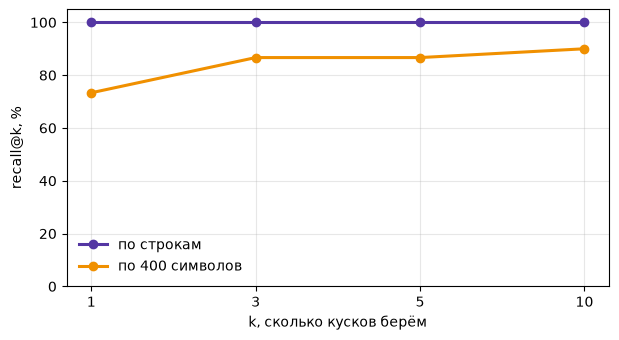

In [5]:
NUMBERS = {word: str(n) for n, word in enumerate("zero one two three four five six seven eight nine ten eleven twelve".split())}


def norm(text):
    words = re.sub(r"\b(a|an|the)\b|[^\w\s]", " ", str(text).lower()).split()
    return " ".join(NUMBERS.get(w, w) for w in words)


def is_gold(chunk, task):
    if task["answer"] is None or chunk["page"] != task["page"]:
        return False
    text, words = norm(chunk["text"]), norm(task["evidence"]).split()
    return norm(task["answer"]) in text and sum(w in text for w in words) >= 0.5 * len(words)


def search_numpy(query_vec, vectors, k=5):
    sims = vectors @ query_vec
    top = np.argsort(-sims)[:k]
    return [(int(i), float(sims[i])) for i in top]


def recall_of(rankings, chunks, k=5):
    return float(np.mean([any(is_gold(chunks[i], t) for i in r[:k]) for r, t in zip(rankings, answerable)]))


KS = (1, 3, 5, 10)
by_vector = {"по строкам": [[i for i, _ in search_numpy(q, line_vecs, 20)] for q in q_vecs],
             "по 400 символов": [[i for i, _ in search_numpy(q, char_vecs, 20)] for q in q_vecs]}
cuts = {"по строкам": line_chunks, "по 400 символов": char_chunks}
curves = {name: {k: recall_of(by_vector[name], cuts[name], k) for k in KS} for name in cuts}

fig, ax = plt.subplots(figsize=(7, 3.6))
for (name, curve), color in zip(curves.items(), [COLORS["violet"], COLORS["amber"]]):
    ax.plot([str(k) for k in curve], [v * 100 for v in curve.values()], marker="o", lw=2.2, color=color, label=name)
ax.set_xlabel("k, сколько кусков берём"); ax.set_ylabel("recall@k, %"); ax.set_ylim(0, 105)
ax.legend(frameon=False); ax.grid(alpha=0.3)
fig.savefig(IMG / "hw2_recall.png", dpi=150, bbox_inches="tight")
pd.DataFrame(curves).round(2)

In [6]:
# k выбираем как самое маленькое, после которого кривая почти не растёт: дальше платим токенами за шум
best = curves["по строкам"]
K = next(k for k in KS if best[max(KS)] - best[k] <= 0.03)
# инструменту агента даём запас: с фильтром или переформулированным запросом верная строка может быть не первой,
# а лишний шаг агента стоит дороже четырёх лишних строк
KB_K = max(K, 5)
print(f"выбранное k = {K}: recall@{K} = {best[K]:.2f}, а recall@{max(KS)} = {best[max(KS)]:.2f}; knowledge_base отдаёт {KB_K}")

выбранное k = 1: recall@1 = 1.00, а recall@10 = 1.00; knowledge_base отдаёт 5


In [7]:
client = MilvusClient(uri="http://localhost:19530")
client.get_server_version(), client.list_collections()

('2.6.24', ['hw2_chars', 'hw2_facts', 'hw2_lines'])

In [8]:
def index_to_milvus(name, chunks, vectors):
    if client.has_collection(name):
        client.drop_collection(name)
    client.create_collection(name, dimension=vectors.shape[1], metric_type="COSINE", consistency_level="Strong")
    rows = [{"id": i, "vector": v.tolist(), **c} for i, (c, v) in enumerate(zip(chunks, vectors))]
    for i in range(0, len(rows), 1000):
        client.insert(name, rows[i:i + 1000])
    client.flush(name)
    return client.get_collection_stats(name)


def search_milvus(name, query, k=5, flt=""):
    vector = embed_cached([query])[0].tolist()
    hits = client.search(name, data=[vector], limit=k, filter=flt, output_fields=["page", "section", "month", "url", "text"])[0]
    return [{**h["entity"], "id": h["id"], "score": round(h["distance"], 4)} for h in hits]


index_to_milvus("hw2_lines", line_chunks, line_vecs), index_to_milvus("hw2_chars", char_chunks, char_vecs)

({'row_count': 3160}, {'row_count': 1325})

In [9]:
# фильтр по документу и по дате (месяцу): та же формулировка с фильтром и без
query = "AI chips deal"
flt = 'page == "2026 in the United States" and month == "February"'
pd.concat([pd.DataFrame(search_milvus("hw2_lines", query, 3)).assign(filter="нет"),
           pd.DataFrame(search_milvus("hw2_lines", query, 3, flt)).assign(filter=flt)])[["filter", "score", "page", "month", "text"]]

,filter,score,page,month,text
0,нет,0.5463,2026 in the United States,September,Chipmaker Nvidia agrees to buy the Hugging Fac...
1,нет,0.5048,2026 in the United States,February,Meta agrees to purchase millions of artificial...
2,нет,0.4006,2026 in science,August,A team of researchers combine synthetic DNA an...
0,"page == ""2026 in the United States"" and month ...",0.5048,2026 in the United States,February,Meta agrees to purchase millions of artificial...
1,"page == ""2026 in the United States"" and month ...",0.2715,2026 in the United States,February,Anthropic rejects a Pentagon request to loosen...
2,"page == ""2026 in the United States"" and month ...",0.1920,2026 in the United States,February,"White House ""border czar"" Tom Homan announces ..."


In [10]:
def tokens(text):
    return re.findall(r"\w+", text.lower())


def build_keyword_index(texts):
    docs = [set(tokens(text)) for text in texts]
    df = {}
    for d in docs:
        for w in d:
            df[w] = df.get(w, 0) + 1
    return docs, {w: np.log(len(docs) / n) for w, n in df.items()}


def keyword_search(query, docs, idf, k=20):
    q = set(tokens(query))
    scores = np.array([sum(idf.get(w, 0.0) for w in q & d) for d in docs])
    return [int(i) for i in np.argsort(-scores)[:k]]


def rrf(rankings, k=5, K=60):
    scores = {}
    for ranking in rankings:
        for rank, idx in enumerate(ranking):
            scores[idx] = scores.get(idx, 0.0) + 1 / (K + rank + 1)
    return sorted(scores, key=scores.get, reverse=True)[:k]


# гибрид на наивной нарезке: на строках вектор уже даёт recall@1 = 1.0, сравнивать там нечего
cut = "по 400 символов"
docs, idf = build_keyword_index([emb_text(c) for c in cuts[cut]])
by_words = [keyword_search(t["question"], docs, idf, 20) for t in answerable]
by_hybrid = [rrf([v, w], 20) for v, w in zip(by_vector[cut], by_words)]
hybrid = pd.DataFrame([{"поиск": name, **{f"recall@{k}": recall_of(r, cuts[cut], k) for k in KS}}
                       for name, r in [("вектор", by_vector[cut]), ("слова", by_words), ("гибрид RRF", by_hybrid)]]).round(2)
hybrid

,поиск,recall@1,recall@3,recall@5,recall@10
0,вектор,0.73,0.87,0.87,0.90
1,слова,0.90,0.97,0.97,0.97
2,гибрид RRF,0.80,0.90,0.93,0.97


## Шаг 3. RAG-ответ, инструмент агента и замер

In [1]:
RAG_SYSTEM = ("Answer the question using only the numbered sources. Cite the source number like [2]. "
              "If the sources do not contain the answer, reply exactly NOT_FOUND. The last line must be FINAL: <short answer>.")
PLAIN_SYSTEM = "Answer the question. If you do not know, reply NOT_FOUND. The last line must be FINAL: <short answer>."
COLLECTION = "hw2_lines"


def format_sources(hits):
    return "\n".join(f"[{i + 1}] ({h['page']}, {h['section'] or '-'}) {h['text']}" for i, h in enumerate(hits))


def rag_answer(question, model, k=None):
    hits = search_milvus(COLLECTION, question, k or K)
    before = ledger.mine
    msg = chat([{"role": "system", "content": RAG_SYSTEM},
                {"role": "user", "content": f"Sources:\n{format_sources(hits)}\n\nQuestion: {question}"}], model, tag="rag")
    return {"answer": msg.get("content") or "", "hits": hits, "cost": ledger.mine - before}


def plain_answer(question, model):
    before = ledger.mine
    msg = chat([{"role": "system", "content": PLAIN_SYSTEM}, {"role": "user", "content": question}], model, tag="plain")
    return {"answer": msg.get("content") or "", "hits": [], "cost": ledger.mine - before}


def final_answer(text):
    m = re.findall(r"FINAL:\s*(.+)", text or "")
    return m[-1].strip() if m else (text or "").strip()


def is_refusal(answer):
    return "NOT_FOUND" in (answer or "")


def is_correct(task, answer):
    if task["answer"] is None:
        return is_refusal(answer)
    return f" {norm(task['answer'])} " in f" {norm(final_answer(answer))} "


In [12]:
TOOLS = {}


def register(fn, args_model, description):
    TOOLS[fn.__name__] = {"fn": fn, "args": args_model, "schema": {"type": "function", "function": {
        "name": fn.__name__, "description": description, "parameters": args_model.model_json_schema()}}}


def run_tool(call):
    name = call["function"]["name"]
    try:
        spec = TOOLS[name]
        result = spec["fn"](**spec["args"].model_validate_json(call["function"]["arguments"]).model_dump())
    except Exception as e:
        result = f"ошибка инструмента {name}: {e}"
    return {"role": "tool", "tool_call_id": call["id"], "content": str(result)[:3000]}


def run_agent(question, model, tool_names, system, max_steps=6):
    messages, seen, before = [{"role": "system", "content": system}, {"role": "user", "content": question}], set(), ledger.mine
    schemas = [TOOLS[n]["schema"] for n in tool_names]
    for step in range(max_steps):
        msg = chat(messages, model, tools=schemas, tag="agent")
        messages.append(msg)
        calls = msg.get("tool_calls") or []
        if not calls:
            break
        keys = {(c["function"]["name"], c["function"]["arguments"]) for c in calls}
        if keys & seen or step == max_steps - 1:
            messages += [{"role": "tool", "tool_call_id": c["id"], "content": "call rejected: answer from what you already have"} for c in calls]
            msg = chat(messages, model, tag="agent")
            break
        seen |= keys
        messages += [run_tool(c) for c in calls]
    return {"answer": msg.get("content") or "", "cost": ledger.mine - before}

In [13]:
# живой поиск по Википедии, как в первой домашке
WIKI = "https://en.wikipedia.org/w/api.php"
WIKI_HEADERS = {"User-Agent": "agents-course-hw02/1.0 (educational project)"}


def wiki(params, attempts=3):
    for attempt in range(attempts):
        r = requests.get(WIKI, params={**params, "format": "json"}, headers=WIKI_HEADERS, timeout=15)
        if r.status_code == 200 and r.headers.get("content-type", "").startswith("application/json"):
            return r.json()["query"]
        time.sleep(1.0 + attempt)
    raise RuntimeError(f"Википедия ответила {r.status_code}")


class SearchArgs(BaseModel):
    query: str = Field(description="short search query: name, title, term")


class PageFindArgs(BaseModel):
    title: str = Field(description="exact Wikipedia article title")
    keywords: str = Field(description="keywords in the language of the article")


def web_search(query: str) -> str:
    hits = wiki({"action": "query", "list": "search", "srsearch": query, "srlimit": 1})["search"]
    if not hits:
        return "No data"
    pages = wiki({"action": "query", "prop": "extracts", "explaintext": 1, "exintro": 1, "titles": hits[0]["title"]})["pages"]
    text = " ".join(next(iter(pages.values())).get("extract", "").split())
    return f"[{hits[0]['title']}] {text[:5000]}"


def page_find(title: str, keywords: str) -> str:
    words = re.findall(r"\w+", keywords.lower())
    if not words:
        return "Provide non-empty keywords"
    pages = wiki({"action": "query", "prop": "extracts", "explaintext": 1, "redirects": 1, "titles": title})["pages"]
    text = next(iter(pages.values())).get("extract", "")
    if not text:
        return "No such page or empty extract"
    lines = [line.strip() for line in text.splitlines() if any(w in line.lower() for w in words)]
    lines.sort(key=lambda line: -sum(w in line.lower() for w in words))
    if not lines:
        return "Keywords not found on the page"
    return f"[{title}]\n" + "\n".join(line[:500] for line in lines[:6])[:1900]


register(web_search, SearchArgs, "Searches English Wikipedia and returns the intro of the best matching article")
register(page_find, PageFindArgs, "Reads the full text of a Wikipedia article and returns lines matching the keywords. "
                                  "Use it when the intro has no answer.")

LIVE_SYSTEM = ("You answer questions about events of 2026. Never answer from memory: look facts up with the tools, do not repeat the same call. "
               "When done, write the last line as FINAL: <short answer>, or NOT_FOUND if you could not find the answer.")


def live_agent(question, model):
    return {**run_agent(question, model, ["web_search", "page_find"], LIVE_SYSTEM, max_steps=8), "hits": []}

In [14]:
# knowledge_base: поиск по нашей базе в Milvus. Найденные куски складываем в журнал потока,
# чтобы потом проверить, нашёл ли агент верный кусок (кучка «поиск не нашёл» в разборе провалов)
KB_LOG = threading.local()
PAGES = sorted({c["page"] for c in line_chunks})


class KBArgs(BaseModel):
    query: str = Field(description="short search query in English: names, companies, key terms of the event")
    page: str = Field(default="", description=f"optional page to search within, one of: {', '.join(PAGES)}; empty means all pages")
    month: str = Field(default="", description="optional month of the event in English, for example 'March'; empty means any month")


def kb_filter(page="", month=""):
    parts = []
    if page:
        parts.append(f'page == "{page.replace(chr(34), "")}"')
    if month:
        parts.append(f'month == "{month.strip().capitalize()}"')
    return " and ".join(parts)


def knowledge_base(query: str, page: str = "", month: str = "") -> str:
    hits = search_milvus(COLLECTION, query, KB_K, kb_filter(page, month))
    if hasattr(KB_LOG, "hits"):
        KB_LOG.hits += hits
    if not hits:
        return "nothing found"
    return "\n".join(f"[{h['page']} / {h['section'] or '-'}] {h['text']}" for h in hits)


register(knowledge_base, KBArgs, "Searches the local knowledge base of 2026 events (Wikipedia pages '2026 in ...') "
                                 "and returns the closest facts with their page and month. Filters by page and month are optional.")

KB_SYSTEM = ("You answer questions about events of 2026. Never answer from memory: look facts up in knowledge_base, "
             "rephrase the query if the first search misses, do not repeat the same call. "
             "When done, write the last line as FINAL: <short answer>, or NOT_FOUND if the knowledge base has no answer.")


def kb_agent(question, model):
    KB_LOG.hits = []
    out = run_agent(question, model, ["knowledge_base"], KB_SYSTEM)
    return {**out, "hits": KB_LOG.hits}

In [15]:
# тест knowledge_base на три случая, без модели и без Milvus: подменяем search_milvus
fake_hits = [{"page": "2026 in science", "section": "September", "month": "September", "url": "", "text": "OpenAI launches GPT-6.", "id": 1, "score": 0.7}]


def broken_search(*args, **kwargs):
    raise RuntimeError("Milvus недоступен")


with patch(f"{__name__}.search_milvus", lambda *a, **kw: fake_hits):
    assert knowledge_base("GPT-6 launch") == "[2026 in science / September] OpenAI launches GPT-6."  # нормальный ответ
with patch(f"{__name__}.search_milvus", lambda *a, **kw: []):
    assert knowledge_base("unknown thing", page="2026 in France") == "nothing found"                 # пустой результат
with patch(f"{__name__}.search_milvus", broken_search):
    call = {"id": "t", "function": {"name": "knowledge_base", "arguments": json.dumps({"query": "x"})}}
    assert "ошибка инструмента knowledge_base" in run_tool(call)["content"]                          # ошибка
"knowledge_base: тесты пройдены"

'knowledge_base: тесты пройдены'

In [16]:
def evaluate(fn, sample, config, model, workers=8):
    def one(task):
        try:
            out = fn(task["question"], model)
        except Exception as e:
            out = {"answer": f"ошибка: {e}", "hits": [], "cost": 0.0}
        return {"config": config, "model": model.split("/")[-1], "id": task["id"], "answerable": task["answer"] is not None,
                "correct": is_correct(task, out["answer"]), "found": any(is_gold(h, task) for h in out["hits"]),
                "refused": is_refusal(out["answer"]), "cost": out["cost"],
                "answer": final_answer(out["answer"])[:200], "gold": task["answer"], "question": task["question"],
                "hits": [{k: h.get(k) for k in ("page", "section", "text")} for h in out["hits"]][:10]}

    with ThreadPoolExecutor(workers) as pool:
        frame = pd.DataFrame(list(pool.map(one, sample)))
    errors = frame[frame["answer"].str.startswith("ошибка:")]
    if len(errors):  # упавший вызов API считался бы неверным ответом, поэтому показываем такие явно
        print(f"{config} / {model}: {len(errors)} вопросов упали с ошибкой API, например: {errors['answer'].iloc[0]}")
    return frame


def report(results):
    # доля верных и цена считаются по вопросам с ответом; отказы отдельной таблицей ниже
    g = results[results["answerable"]].groupby(["config", "model"], sort=False)
    table = g.agg(n=("correct", "size"), accuracy=("correct", "mean"), cost_per_task=("cost", "mean")).reset_index()
    table["cost_per_correct"] = table["cost_per_task"] / table["accuracy"].replace(0, float("nan"))
    return table.round(5)


def refusals(results):
    g = results.groupby(["config", "model"], sort=False)
    return g.apply(lambda d: pd.Series({
        "честно отклонено (из 10 без ответа)": int((d["refused"] & ~d["answerable"]).sum()),
        "зря отклонено (из 30 с ответом)": int((d["refused"] & d["answerable"]).sum())}), include_groups=False).reset_index()


def money_chart(table, path):
    fig, ax = plt.subplots(figsize=(8, 4.6))
    for _, r in table.iterrows():
        color = COLORS["amber"] if "sonnet" in r["model"] else COLORS["teal"] if "haiku" in r["model"] else COLORS["violet"]
        ax.scatter(r["cost_per_task"] * 100, r["accuracy"] * 100, s=110, color=color)
        ax.annotate(f"{r['config']}\n{r['model']}", (r["cost_per_task"] * 100, r["accuracy"] * 100), fontsize=8,
                    xytext=(7, 3), textcoords="offset points")
    ax.set_xscale("log"); ax.set_xlabel("цена вопроса, центы (логарифмическая шкала)"); ax.set_ylabel("доля верных, %")
    ax.set_ylim(0, 105); ax.grid(alpha=0.3)
    fig.savefig(path, dpi=150, bbox_inches="tight")
    return fig

In [17]:
results = pd.concat([
    evaluate(plain_answer, tasks, "сильная, без инструментов", MODELS["strong"]),
    evaluate(live_agent, tasks, "дешёвая, живой поиск", MODELS["cheap"], workers=4),
    evaluate(rag_answer, tasks, f"дешёвая, RAG всегда, k={K}", MODELS["cheap"]),
    evaluate(kb_agent, tasks, "дешёвая, агент с knowledge_base", MODELS["cheap"]),
    evaluate(rag_answer, tasks, f"средняя, RAG всегда, k={K}", MODELS["mid"]),
], ignore_index=True)
table = report(results)
table

,config,model,n,accuracy,cost_per_task,cost_per_correct
0,"сильная, без инструментов",claude-sonnet-4.6,30,0.00000,0.00119,NaN
1,"дешёвая, живой поиск",gpt-4o-mini,30,0.10000,0.00053,0.00530
2,"дешёвая, RAG всегда, k=1",gpt-4o-mini,30,1.00000,0.00004,0.00004
3,"дешёвая, агент с knowledge_base",gpt-4o-mini,30,0.76667,0.00035,0.00046
4,"средняя, RAG всегда, k=1",claude-haiku-4.5,30,1.00000,0.00041,0.00041


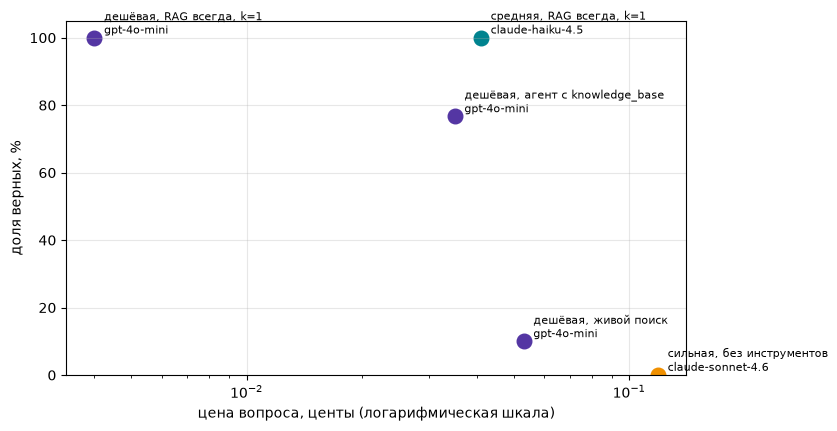

In [18]:
money_chart(table, IMG / "hw2_money_chart.png");

In [19]:
refusals(results)

,config,model,честно отклонено (из 10 без ответа),зря отклонено (из 30 с ответом)
0,"сильная, без инструментов",claude-sonnet-4.6,10,28
1,"дешёвая, живой поиск",gpt-4o-mini,8,26
2,"дешёвая, RAG всегда, k=1",gpt-4o-mini,10,1
3,"дешёвая, агент с knowledge_base",gpt-4o-mini,10,6
4,"средняя, RAG всегда, k=1",claude-haiku-4.5,10,0


## Шаг 4. Память

In [22]:
JOURNAL = MEMORY_DIR / "episodes.jsonl"


def fact_id(key):
    return int(hashlib.sha1(key.strip().lower().encode("utf-8")).hexdigest()[:15], 16)


class FactStore:
    def __init__(self, name, embed):
        self.name, self.embed = name, embed

    def reset(self):
        if client.has_collection(self.name):
            client.drop_collection(self.name)

    def upsert(self, facts):
        if not facts:
            return
        if not client.has_collection(self.name):
            client.create_collection(self.name, dimension=DIM, metric_type="COSINE", consistency_level="Strong")
        vectors = self.embed([f"{f['key']}: {f['text']}" for f in facts])
        client.upsert(self.name, [{"id": fact_id(f["key"]), "vector": v.tolist(), "key": f["key"], "text": f["text"]}
                                  for f, v in zip(facts, vectors)])
        client.flush(self.name)

    def all(self):
        if not client.has_collection(self.name):
            return []
        return [{"key": r["key"], "text": r["text"]} for r in client.query(self.name, filter="", limit=1000, output_fields=["key", "text"])]

    def recall(self, query, k=3):
        if not client.has_collection(self.name):
            return []
        hits = client.search(self.name, data=[self.embed([query])[0].tolist()], limit=k, output_fields=["key", "text"])[0]
        return [{"key": h["entity"]["key"], "text": h["entity"]["text"]} for h in hits]


def fake_embed(texts):
    # детерминированный «эмбеддинг» для тестов без API: мешок слов, разложенный хешем по DIM ячейкам
    out = np.zeros((len(texts), DIM), dtype=np.float32)
    for row, text in enumerate(texts):
        for w in tokens(text):
            out[row, int(hashlib.md5(w.encode()).hexdigest(), 16) % DIM] += 1.0
    return out / np.maximum(np.linalg.norm(out, axis=1, keepdims=True), 1e-9)

In [23]:
# тесты памяти без модели: пустая память, найденный факт, заменённый факт
store = FactStore("hw2_facts_test", fake_embed)
store.reset()
assert store.recall("где живёт пользователь") == [] and store.all() == []                        # пустая память
store.upsert([{"key": "city", "text": "живёт в Москве"}, {"key": "job", "text": "работает бэкенд разработчиком"},
              {"key": "interests", "text": "следит за чипами и AI"}])
assert store.recall("кем работает пользователь", 1)[0]["key"] == "job"                           # найденный факт
store.upsert([{"key": "city", "text": "переехал в Берлин"}])
cities = [f for f in store.all() if f["key"] == "city"]
assert len(store.all()) == 3 and cities == [{"key": "city", "text": "переехал в Берлин"}]          # заменённый факт
store.reset()
"память: тесты пройдены"

'память: тесты пройдены'

In [24]:
FACTS_SYSTEM = ("Ты ведёшь память ассистента о пользователе. Верни один JSON-объект вида "
                "{\"facts\": [{\"key\": \"city\", \"text\": \"живёт в Москве\"}]}: только новые или изменившиеся устойчивые факты "
                "о пользователе из диалога. key это короткая тема на английском: name, city, job, interests, answer_style и т.п. "
                "Если факт меняет уже известный, используй ТОТ ЖЕ key, что у известного факта. "
                "Разовые вопросы и мелочи не записывай. Если нового нет, верни {\"facts\": []}.")
ASSISTANT_SYSTEM = ("Ты помощник, который отвечает на вопросы о событиях 2026 года по базе знаний. Отвечай на языке пользователя, "
                    "опирайся на источники и на то, что знаешь о пользователе. Источники подобраны автоматически и могут быть не по теме: "
                    "используй только те, что относятся к вопросу. Если в источниках ответа нет, так и скажи.")


class Fact(BaseModel):
    key: str = Field(description="тема факта: city, job, interests…")
    text: str = Field(description="короткий факт о пользователе")


class Facts(BaseModel):
    facts: list[Fact]


def json_from(text):
    m = re.search(r"\{.*\}", text or "", re.S)
    return json.loads(m.group(0) if m else "{}", strict=False)


def remember_episode(session, role, text):
    with JOURNAL.open("a", encoding="utf-8") as f:
        f.write(json.dumps({"session": session, "time": time.strftime("%Y-%m-%d %H:%M:%S"), "role": role, "text": text},
                           ensure_ascii=False) + "\n")


def extract_facts(dialog, known):
    prompt = f"Известные факты: {json.dumps(known, ensure_ascii=False)}\n\nДиалог:\n{dialog}"
    msg = chat([{"role": "system", "content": FACTS_SYSTEM}, {"role": "user", "content": prompt}], MODELS["cheap"], tag="memory")
    return [f.model_dump() for f in Facts.model_validate(json_from(msg["content"])).facts]


memory = FactStore("hw2_facts", embed_cached)


def talk(session, history, user_text, mode="память"):
    remember_episode(session, "user", user_text)
    facts = [f["text"] for f in memory.recall(user_text)] if mode == "память" else []
    hits = search_milvus(COLLECTION, user_text, K) if "?" in user_text else []
    sources = format_sources(hits) or "нет"
    system = ASSISTANT_SYSTEM + ("\nЧто известно о пользователе: " + "; ".join(facts) if facts else "")
    window = history[-4:] if mode == "память" else history
    msg = chat([{"role": "system", "content": system}] + window + [{"role": "user", "content": f"Источники:\n{sources}\n\n{user_text}"}],
               MODELS["cheap"], tag=f"dialog: {mode}")
    answer = msg.get("content") or ""
    history += [{"role": "user", "content": user_text if mode == "память" else f"Источники:\n{sources}\n\n{user_text}"},
                {"role": "assistant", "content": answer}]
    remember_episode(session, "assistant", answer)
    return answer


def end_session(history):
    dialog = "\n".join(f"{m['role']}: {m['content'][:400]}" for m in history)
    memory.upsert(extract_facts(dialog, memory.all()))
    return memory.all()


JOURNAL.unlink(missing_ok=True)
memory.reset()

In [25]:
# сессия 1: пользователь рассказывает о себе и задаёт вопрос
first = []
print(talk("s1", first, "Привет! Я Саша, бэкенд-разработчик из Москвы. Слежу за AI и рынком чипов, отвечай коротко."))
print(talk("s1", first, "Что произошло с OpenAI Sora в 2026 году?"))
end_session(first)

Привет, Саша! Какой именно вопрос о событиях 2026 года тебя интересует?


В марте 2026 года OpenAI объявила о закрытии своего флагманского приложения Sora и API. Приложение было закрыто 26 апреля, а API — 24 сентября.


[{'key': 'city', 'text': 'живёт в Москве'},
 {'key': 'job', 'text': 'бэкенд-разработчик'},
 {'key': 'name', 'text': 'Саша'},
 {'key': 'interests', 'text': 'слежу за AI и рынком чипов'},
 {'key': 'answer_style', 'text': 'отвечай коротко'}]

In [26]:
# сессия 2: история первой сессии в контекст не попадает, агент знает о пользователе только факты из Milvus
second = []
print(talk("s2", second, "Какие сделки по чипам были в моей теме в 2026 году?"))
print(talk("s2", second, "Кстати, я переехал из Москвы в Берлин."))
end_session(second)

В 2026 году Meta заключила сделку с AMD на покупку миллионов чипов для искусственного интеллекта. AMD обязалась поставлять до шести гигаватт графических процессоров и выдала Meta варранты на конвертацию в 160 миллионов акций в рамках долгосрочного партнерства.


Спасибо за обновление! Если у тебя будут вопросы о событиях в 2026 году или о чем-то еще, не стесняйся спрашивать.


[{'key': 'city', 'text': 'живёт в Берлине'},
 {'key': 'job', 'text': 'бэкенд-разработчик'},
 {'key': 'name', 'text': 'Саша'},
 {'key': 'interests', 'text': 'слежу за AI и рынком чипов'},
 {'key': 'answer_style', 'text': 'отвечай коротко'}]

In [27]:
pd.read_json(JOURNAL, lines=True).tail(8)

,session,time,role,text
0,s1,2026-10-14 23:42:30,user,"Привет! Я Саша, бэкенд-разработчик из Москвы. ..."
1,s1,2026-10-14 23:42:32,assistant,"Привет, Саша! Какой именно вопрос о событиях 2..."
2,s1,2026-10-14 23:42:32,user,Что произошло с OpenAI Sora в 2026 году?
3,s1,2026-10-14 23:42:33,assistant,В марте 2026 года OpenAI объявила о закрытии с...
4,s2,2026-10-14 23:42:39,user,Какие сделки по чипам были в моей теме в 2026 ...
5,s2,2026-10-14 23:42:42,assistant,В 2026 году Meta заключила сделку с AMD на пок...
6,s2,2026-10-14 23:42:42,user,"Кстати, я переехал из Москвы в Берлин."
7,s2,2026-10-14 23:42:43,assistant,Спасибо за обновление! Если у тебя будут вопро...


,prompt,cost
tag,,
dialog: память,4029,0.00090
dialog: вся история,11725,0.00164


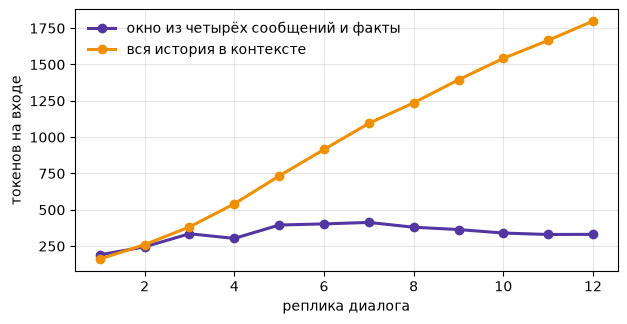

In [28]:
SCRIPT = [t["question"] for t in answerable[:12]]
start = len(ledger.calls)
for mode in ("память", "вся история"):
    history = []
    for q in SCRIPT:
        talk("bench", history, q, mode)
per_turn = pd.DataFrame(ledger.calls[start:])
per_turn = per_turn[per_turn["tag"].str.startswith("dialog: ")]
fig, ax = plt.subplots(figsize=(7, 3.4))
for (tag, part), color in zip(per_turn.groupby("tag", sort=False), [COLORS["violet"], COLORS["amber"]]):
    ax.plot(range(1, len(part) + 1), part["prompt"].values, marker="o", lw=2.2, color=color,
            label={"dialog: память": "окно из четырёх сообщений и факты", "dialog: вся история": "вся история в контексте"}[tag])
ax.set_xlabel("реплика диалога"); ax.set_ylabel("токенов на входе"); ax.legend(frameon=False); ax.grid(alpha=0.3)
fig.savefig(IMG / "hw2_memory_tokens.png", dpi=150, bbox_inches="tight")
per_turn.groupby("tag", sort=False).agg(prompt=("prompt", "sum"), cost=("cost", "sum")).round(5)

In [29]:
ledger.table(), round(ledger.total, 4)

(                                            calls  prompt  completion     cost
 tag                 model                                                     
 agent               gpt-4o-mini               404  248968       11296  0.04242
 dialog: вся история gpt-4o-mini                12   11725         653  0.00164
 dialog: память      gpt-4o-mini                16    4806         664  0.00112
 embed               text-embedding-3-small     10      95           0  0.00000
 memory              gpt-4o-mini                 2     643         111  0.00016
 plain               claude-sonnet-4.6          40    2443        2615  0.04655
 rag                 claude-haiku-4.5           40    5728        2290  0.01718
                     gpt-4o-mini                40    5300        1061  0.00143,
 0.1105)